<a href="https://colab.research.google.com/github/lautrevor/data-science-portfolio/blob/main/02_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Injury Severity Analysis — NCDB 2019–2020

Loading and cleaning is in `01_load_and_clean.ipynb`. This notebook does the analysis.

The database holds 471,046 records — one row per person involved in a police-reported
collision in Canada in 2019 or 2020.

Two questions:

1. Who gets hurt worst, people inside a vehicle or outside it?
2. Does restraint use change the odds of injury once age, weather and year are accounted for?

## Load the repo

Colab sessions start empty and are wiped on disconnect, so the repo is cloned
into the session each time. Everything below runs from the project folder.

In [ ]:
if (!dir.exists("/content/data-science-portfolio")) {
  system("git clone https://github.com/lautrevor/data-science-portfolio.git /content/data-science-portfolio")
}
setwd("/content/data-science-portfolio/project-3-bc-collision-analysis")

getwd()
list.files("sql")

[1] "/content/data-science-portfolio/project-3-bc-collision-analysis"

[1] "01_road_user.sql" "collisions.db"

## Setup

SQL queries are kept as separate files in `sql/` rather than inline, so each one can be read
on its own. `run()` reads one of those files and executes it against the database, returning
an R data frame.

The row count below confirms the connection works and the table is complete.

In [ ]:
pkgs <- c("DBI","RSQLite","dplyr","broom","ggplot2")
need <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(need)) install.packages(need)
library(DBI); library(RSQLite); library(dplyr); library(broom); library(ggplot2)

con <- dbConnect(SQLite(), "sql/collisions.db")
run <- function(path) dbGetQuery(con, paste(readLines(path), collapse = "\n"))

dbGetQuery(con, "SELECT COUNT(*) AS n FROM collisions")

n
<int>
471046


## Question 1 — who gets hurt worst?

Rate per person involved, not per collision. `P_USER` codes: 1 driver, 2 passenger,
3 pedestrian, 4 cyclist, 5 motorcyclist. Rows where injury severity was not recorded
are excluded; the count is reported below.

In [ ]:
writeLines('SELECT
  P_USER,
  COUNT(*) AS persons,
  ROUND(100.0 * SUM(CASE WHEN P_ISEV = 3      THEN 1 ELSE 0 END) / COUNT(*), 2) AS fatality_pct,
  ROUND(100.0 * SUM(CASE WHEN P_ISEV IN (2,3) THEN 1 ELSE 0 END) / COUNT(*), 2) AS harmed_pct
FROM collisions
WHERE P_ISEV IN (1,2,3)
  AND P_USER IN (1,2,3,4,5)
GROUP BY P_USER
ORDER BY fatality_pct DESC;', "sql/01_road_user.sql")

In [ ]:
run("sql/01_road_user.sql")

P_USER,persons,fatality_pct,harmed_pct
<dbl>,<int>,<dbl>,<dbl>
5,11383,3.77,94.96
3,18950,3.17,97.86
4,8989,0.99,96.25
1,280893,0.61,53.45
2,102267,0.55,53.42


Motorcyclists are killed at 3.77% and pedestrians at 3.17%, roughly six and five times
the driver rate of 0.61%.

The injury column is the wider gap. Around 95–98% of people outside a vehicle are
injured or killed, against 53% of drivers and passengers. Half of everyone inside a
vehicle walks away from a reported collision. Almost nobody outside one does.

Cyclists split the difference:

### How much data drops out, and for whom

The injury severity filter does not remove rows evenly across road user types. This
matters because each rate above is computed on a different subset of its group, so
the comparison is not quite like-for-like, and the size of that gap needs stating.

In [ ]:
dbGetQuery(con, "
SELECT
  P_USER,
  COUNT(*) AS total,
  SUM(CASE WHEN P_ISEV IN (1,2,3) THEN 1 ELSE 0 END) AS kept,
  ROUND(100.0 * SUM(CASE WHEN P_ISEV NOT IN (1,2,3) OR P_ISEV IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS dropped_pct
FROM collisions
WHERE P_USER IN (1,2,3,4,5)
GROUP BY P_USER
ORDER BY dropped_pct DESC")

P_USER,total,kept,dropped_pct
<dbl>,<int>,<int>,<dbl>
3,22709,18950,16.6
1,296152,280893,5.2
5,11658,11383,2.4
4,9049,8989,0.7
2,102496,102267,0.2


The injury severity filter does not remove rows evenly. Pedestrians lose 16.6% of their
rows to unrecorded outcomes, drivers 5.2%, motorcyclists 2.4%, cyclists 0.7%, and
passengers 0.2% — a spread of roughly eighty times between the extremes. A further 28,982
rows, 6.2% of the file, were excluded before any of this because the road user type itself
was not recorded.

This matters for the comparison above. The pedestrian rate is computed on a far more
heavily filtered subset than the passenger rate, so if the missing pedestrian outcomes are
not a random sample of pedestrian outcomes, that rate is biased. Nothing in the data says
which direction it runs, and nothing records why pedestrian outcomes go unreported more
often. It cannot be corrected here, only stated.


### How many times the occupant rate?

The table gives each group's fatality rate. To compare them, I divide each rate by the
fatality rate for vehicle occupants (drivers and passengers combined, weighted by how
many people are in each group). A value of 5 means that group dies at five times the
occupant rate.

In [ ]:
ru <- run("sql/01_road_user.sql")
ru$user <- factor(ru$P_USER, 1:5,
                  c("Driver","Passenger","Pedestrian","Cyclist","Motorcyclist"))
occ <- ru %>% filter(P_USER %in% c(1, 2))
occ_rate <- 100 * sum(occ$fatality_pct / 100 * occ$persons) / sum(occ$persons)

ru %>%
  mutate(times_occupant_rate = round(fatality_pct / occ_rate, 1)) %>%
  select(user, persons, fatality_pct, times_occupant_rate)

user,persons,fatality_pct,times_occupant_rate
<fct>,<int>,<dbl>,<dbl>
Motorcyclist,11383,3.77,6.3
Pedestrian,18950,3.17,5.3
Cyclist,8989,0.99,1.7
Driver,280893,0.61,1.0
Passenger,102267,0.55,0.9


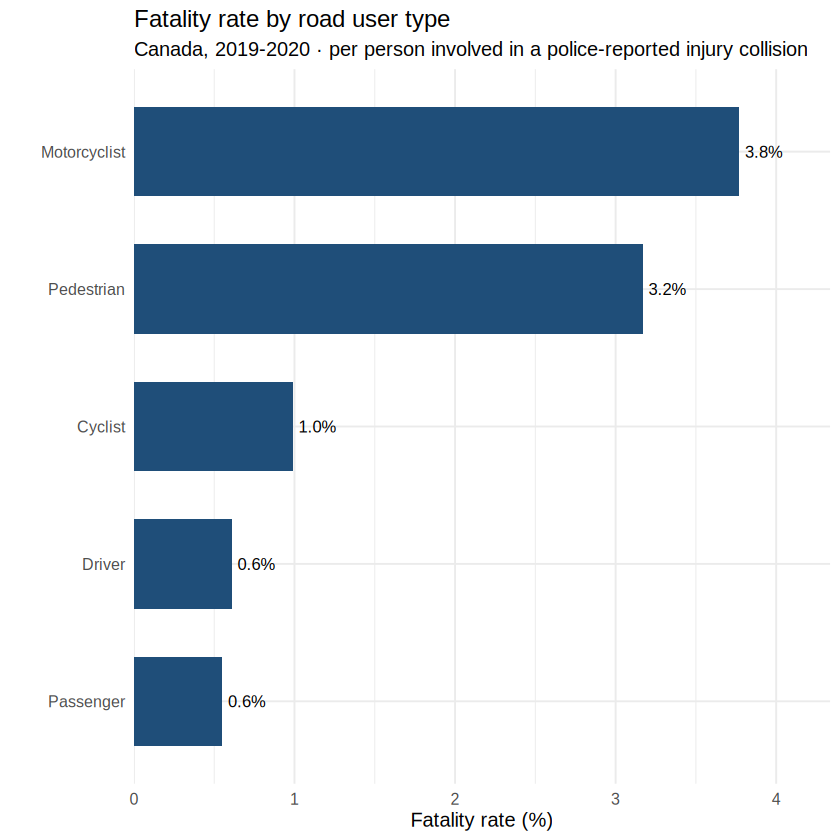

In [ ]:
ggplot(ru, aes(reorder(user, fatality_pct), fatality_pct)) +
  geom_col(width = .65, fill = "#1f4e79") +
  geom_text(aes(label = sprintf("%.1f%%", fatality_pct)), hjust = -0.15, size = 3.5) +
  coord_flip() +
  scale_y_continuous(expand = expansion(mult = c(0, .15))) +
  labs(title = "Fatality rate by road user type",
       subtitle = "Canada, 2019-2020 · per person involved in a police-reported injury collision",
       x = NULL, y = "Fatality rate (%)") +
  theme_minimal(base_size = 12)

ggsave("figures/road_user_fatality.png", width = 8, height = 4.5, dpi = 200)

### What this shows

People outside a vehicle die at several times the rate of people inside one.
Motorcyclists die at **6.3×** the occupant rate and pedestrians at **5.3×**.
Cyclists are at **1.7×**.

**What this does not show.** These are raw rates among people who were already in an
injury collision. The data has no record of everyone who travelled safely, so this says
who gets hurt worst once a crash happens. It says nothing about what causes crashes or
how risky each mode is per trip.

**Caveat.** 16.6% of pedestrian records have unknown injury severity, compared with
0.2% for passengers. Those rows are excluded, so the pedestrian rate is computed on a
more selected group than the others (see the exclusion analysis above).

## Question 2: where are pedestrians most at risk?

Pedestrians die at 5.3 times the occupant rate. The next question is where. This
breaks pedestrian injury collisions down by road configuration (`C_RCFG`): whether the
collision happened at an intersection, between intersections, or somewhere else.

Same outcome filter as Question 1: only people with known injury severity.

In [ ]:
system("git pull")   # picks up the new .sql file from GitHub

ped <- run("sql/02_pedestrians.sql")
ped$C_RCFG <- as.integer(ped$C_RCFG)
ped$config <- case_when(
  ped$C_RCFG == 1 ~ "Not at intersection (mid-block)",
  ped$C_RCFG == 2 ~ "At intersection",
  ped$C_RCFG == 3 ~ "Driveway / parking lot / laneway",
  ped$C_RCFG == 4 ~ "Railroad crossing",
  ped$C_RCFG == 5 ~ "Bridge / overpass",
  ped$C_RCFG == 6 ~ "Tunnel / underpass",
  ped$C_RCFG == 8 ~ "Ramp",
  ped$C_RCFG == 9 ~ "Traffic circle",
  TRUE            ~ paste("Code", ped$C_RCFG)
)
ped

C_RCFG,persons,fatality_pct,config
<int>,<int>,<dbl>,<chr>
2,10746,1.94,At intersection
1,4656,6.59,Not at intersection (mid-block)
3,912,2.74,Driveway / parking lot / laneway
8,25,0.00,Ramp
4,25,0.00,Railroad crossing
5,20,5.00,Bridge / overpass
9,13,0.00,Traffic circle
6,4,50.00,Tunnel / underpass


### Chart: pedestrian fatality rate by road configuration

Only configurations with at least 100 pedestrians are shown. Smaller groups give
unstable rates.

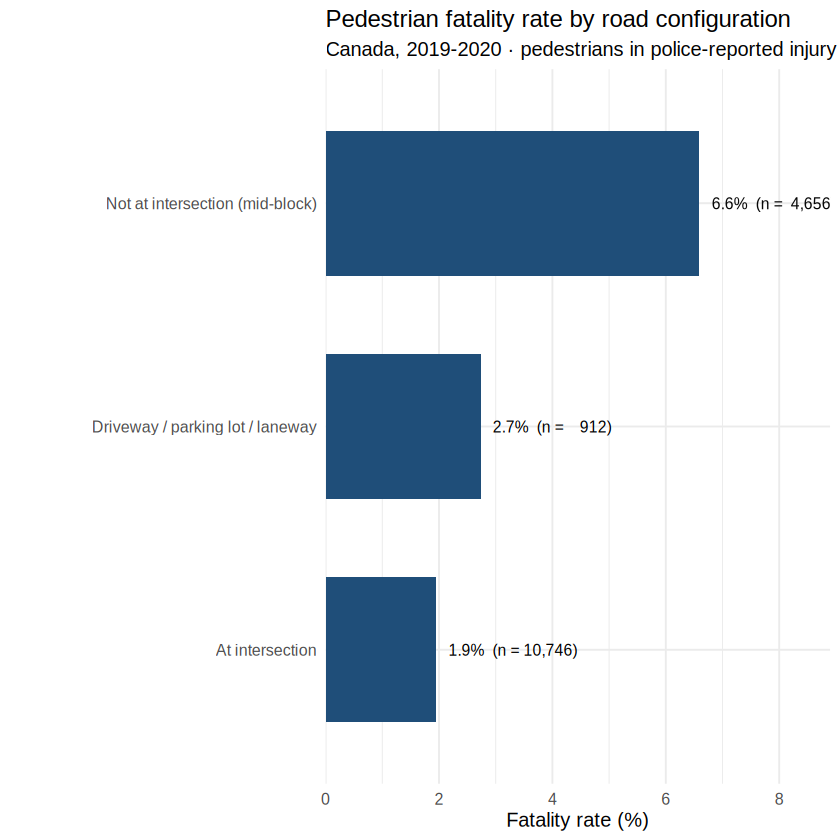

In [ ]:
ped_plot <- ped %>% filter(persons >= 100)

ggplot(ped_plot, aes(reorder(config, fatality_pct), fatality_pct)) +
  geom_col(width = .65, fill = "#1f4e79") +
  geom_text(aes(label = sprintf("%.1f%%  (n = %s)", fatality_pct,
                                format(persons, big.mark = ","))),
            hjust = -0.1, size = 3.3) +
  coord_flip() +
  scale_y_continuous(expand = expansion(mult = c(0, .35))) +
  labs(title = "Pedestrian fatality rate by road configuration",
       subtitle = "Canada, 2019-2020 · pedestrians in police-reported injury collisions",
       x = NULL, y = "Fatality rate (%)") +
  theme_minimal(base_size = 12)

ggsave("figures/pedestrian_road_config.png", width = 8, height = 4.5, dpi = 200)

In [ ]:
# Do the pedestrian flags agree? Zero is the clean answer.
dbGetQuery(con, "
SELECT COUNT(*) AS disagreements
FROM collisions
WHERE P_USER = 3 AND (P_PSN <> 99 OR V_ID <> 99)")

disagreements
<int>
1


 **Data check.** Only 1 pedestrian record has position or vehicle codes that contradict
the pedestrian flag, so the pedestrian coding is consistent.